In [18]:
import pandas as pd
import numpy as np

In [19]:
df = pd.read_csv(
    r"C:\Users\omark\Desktop\My python\household_power_consumption.txt",
    sep=";",
    na_values="?",
    low_memory=False
)

In [20]:
df.shape

(2075259, 9)

In [21]:
df.columns

Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 142.5 MB


In [23]:
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [24]:
df. isnull().sum()           # Count the missing values in each column

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [25]:
df.isnull().sum() / len(df) * 100

Date                     0.000000
Time                     0.000000
Global_active_power      1.251844
Global_reactive_power    1.251844
Voltage                  1.251844
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64

In [26]:
df[df.isnull().any(axis=1)].head(10)             #



,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
6839,21/12/2006,11:23:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6840,21/12/2006,11:24:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19724,30/12/2006,10:08:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19725,30/12/2006,10:09:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41832,14/1/2007,18:36:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
61909,28/1/2007,17:13:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
98254,22/2/2007,22:58:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
98255,22/2/2007,22:59:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
142588,25/3/2007,17:52:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
190497,28/4/2007,00:21:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
df.isnull().any(axis=1).sum()                      # number of rows containing at least one missing value.

np.int64(25979)

In [28]:
missing = df['Global_active_power'].isnull()
groups = (missing != missing.shift()).cumsum()
missing_lengths = missing.groupby(groups).sum()

missing_lengths.max()

np.int64(7226)

In [29]:
missing_lengths = missing_lengths[missing_lengths > 0]
missing_lengths.describe()

count      71.000000
mean      365.901408
std      1251.468043
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max      7226.000000
Name: Global_active_power, dtype: float64

### Converting Date and Time into Datetime

The Date and Time columns are combined and converted into
a single Datetime column. This allows us to perform
time-series analysis, verify time intervals, and analyse
electricity consumption by hour, day, and month.

In [30]:
# Combine Date and Time and convert them into datetime format
df['Datetime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Time'],
    format='%d/%m/%Y %H:%M:%S',
    errors='coerce'
)

# Display the first five rows
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00


### Verifying Datetime Conversion

Check for invalid timestamps, confirm the datetime
data type, and verify that the observations are
arranged in chronological order.

In [31]:
# Check the data type of the Datetime column
print("Data type:", df['Datetime'].dtype)

# Count missing or invalid timestamps
print("Invalid timestamps:", df['Datetime'].isnull().sum())

# Check if timestamps are arranged in chronological order
print("Chronological order:", df['Datetime'].is_monotonic_increasing)

Data type: datetime64[us]
Invalid timestamps: 0
Chronological order: True


### Checking Time Intervals

Calculate the time difference between consecutive
timestamps to verify that measurements are recorded
at regular one-minute intervals and identify any
missing or repeated timestamps.

In [32]:
# Calculate the time difference between consecutive timestamps
time_diff = df['Datetime'].diff()

# Count how many times each time interval occurs
time_diff.value_counts()

# All consecutive timestamps are separated by exactly one minute.
# This confirms that the dataset has a consistent sampling interval
# with no missing or repeated timestamps.

Datetime
0 days 00:01:00    2075258
Name: count, dtype: int64

### Detecting Duplicate Records

Check for completely duplicated rows and repeated
timestamps to ensure that electrical measurements
are not recorded more than once for the same time.

In [33]:
# Count completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Count repeated timestamps
print("Duplicate timestamps:", df['Datetime'].duplicated().sum())

Duplicate rows: 0
Duplicate timestamps: 0


In [34]:
# No duplicate rows or duplicate timestamps were found.
# No duplicate removal is required.

### Classifying Missing Gaps

Classify consecutive missing measurements into short
and long gaps to determine an appropriate missing
value treatment method for each category.

In [36]:
# Identify gaps containing three or fewer missing measurements
short_gaps = missing_lengths[missing_lengths <= 3]

# Identify gaps containing more than three missing measurements
long_gaps = missing_lengths[missing_lengths > 3]

# Count the number of gaps in each category
print("Number of short gaps:", len(short_gaps))
print("Number of long gaps:", len(long_gaps))

# Count the missing measurements in each category
print("Missing values in short gaps:", short_gaps.sum())
print("Missing values in long gaps:", long_gaps.sum())

Number of short gaps: 54
Number of long gaps: 17
Missing values in short gaps: 72
Missing values in long gaps: 25907


In [ ]:
# Most missing gaps are short, but long gaps contain
# approximately 99.72% of all missing measurements.
# Linear interpolation will be used only for short gaps.

### Linear Interpolation of Short Missing Gaps

Apply linear interpolation to missing gaps containing
three or fewer consecutive missing measurements.
Longer gaps remain unfilled to avoid introducing
unreliable estimated values.

In [37]:
# Select electrical measurement columns
measurement_cols = df.columns[2:9]

# Identify missing rows belonging to short gaps
short_gap_mask = groups.isin(short_gaps.index)

# Calculate interpolated values
interpolated = df[measurement_cols].interpolate(
    method='linear',
    limit_area='inside'
)

# Apply interpolated values only to short gaps
df.loc[short_gap_mask, measurement_cols] = interpolated.loc[
    short_gap_mask, measurement_cols
]

# Check remaining missing values
df[measurement_cols].isnull().sum()

Global_active_power      25907
Global_reactive_power    25907
Voltage                  25907
Global_intensity         25907
Sub_metering_1           25907
Sub_metering_2           25907
Sub_metering_3           25907
dtype: int64

In [ ]:
#First, I selected the electrical measurement columns. 
# Then, I created a Boolean mask to identify rows belonging to short missing gaps.
#  I calculated interpolated values in a temporary DataFrame and used the mask to transfer only the 
# short-gap estimates into the original dataset. This allowed me to treat short gaps without 
# introducing unreliable estimated values into long gaps.
#  Finally, I checked the remaining number of missing values.

### Handling Remaining Missing Values

Remove observations containing remaining missing
electrical measurements from a separate DataFrame.
Long missing gaps are excluded rather than estimated
to avoid introducing unreliable artificial data.

In [38]:
# Create a cleaned DataFrame by excluding missing measurements
df_clean = df.dropna(subset=measurement_cols).copy()

# Display the number of rows before and after removal
print("Original rows:", len(df))
print("Remaining rows:", len(df_clean))
print("Removed rows:", len(df) - len(df_clean))

# Check remaining missing values
df_clean.isnull().sum()

Original rows: 2075259
Remaining rows: 2049352
Removed rows: 25907


Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
Datetime                 0
dtype: int64

### Detecting Inconsistent and Invalid Data

Check the electrical measurement columns for negative
values and invalid voltage measurements to identify
potential measurement errors and inconsistent data.

In [40]:
# Count negative values in each electrical measurement column
negative_values = (df_clean[measurement_cols] < 0).sum()

print("Negative values:")
print(negative_values)

# Check for zero or negative voltage measurements
print("Invalid voltage values:", (df_clean['Voltage'] <= 0).sum())

Negative values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64
Invalid voltage values: 0


### Checking Energy Consumption Consistency

Convert total active power from kW into Wh for each
one-minute interval and compare it with the sum of
the three sub-metering measurements to identify
potential energy measurement inconsistencies.

In [47]:
# Convert total active power into energy in Wh
total_energy = df_clean['Global_active_power'] * 1000 / 60

# Calculate the sum of the three sub-metering measurements
sub_metering_total = (
    df_clean['Sub_metering_1']
    + df_clean['Sub_metering_2']
    + df_clean['Sub_metering_3']
)

# Calculate the remaining unmetered energy
remaining_energy = total_energy - sub_metering_total

# Count observations with negative remaining energy
print("Potential inconsistencies:", (remaining_energy < 0).sum())

# Display descriptive statistics
remaining_energy.describe()


Potential inconsistencies: 1050


count    2.049352e+06
mean     9.314978e+00
std      9.586202e+00
min     -2.400000e+00
25%      3.800000e+00
50%      5.500000e+00
75%      1.036667e+01
max      1.248333e+02
dtype: float64

### Investigating Energy Inconsistencies

Analyse the frequency and magnitude of negative
remaining energy values to determine whether they
represent significant measurement inconsistencies.

In [48]:
# Select observations with negative remaining energy
inconsistent_energy = remaining_energy[remaining_energy < 0]

# Calculate the percentage of inconsistent observations
percentage = len(inconsistent_energy) / len(df_clean) * 100

print("Percentage of inconsistencies:", percentage)

# Analyse the magnitude of the negative differences
inconsistent_energy.describe()

Percentage of inconsistencies: 0.05123570767735363


count    1050.000000
mean       -0.293651
std         0.259928
min        -2.400000
25%        -0.333333
50%        -0.233333
75%        -0.166667
max        -0.033333
dtype: float64

In [ ]:
# Only 0.0512% of observations show energy inconsistencies.
# The average negative discrepancy is approximately 0.294 Wh.
# These observations are retained because the discrepancies
# are generally small and may result from measurement errors
# or rounding differences.

### Outlier Detection Using the IQR Method

Calculate the first and third quartiles and the
interquartile range of global active power.
Determine the lower and upper boundaries to
identify potential statistical outliers.

In [49]:
# Calculate the first and third quartiles
Q1 = df_clean['Global_active_power'].quantile(0.25)
Q3 = df_clean['Global_active_power'].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Calculate the lower and upper outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Display the calculated values
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 0.308
Q3: 1.528
IQR: 1.22
Lower bound: -1.522
Upper bound: 3.358


### Counting and Investigating Outliers

Identify observations outside the calculated IQR
boundaries, calculate their percentage, and analyse
their statistical characteristics before deciding
whether any treatment is necessary.

In [50]:
# Select observations outside the IQR boundaries
outliers = df_clean[
    (df_clean['Global_active_power'] < lower_bound) |
    (df_clean['Global_active_power'] > upper_bound)
]

# Count the detected outliers
print("Number of outliers:", len(outliers))

# Calculate the percentage of outliers
print("Percentage of outliers:", len(outliers) / len(df_clean) * 100)

# Display descriptive statistics of the detected outliers
outliers['Global_active_power'].describe()

Number of outliers: 94919
Percentage of outliers: 4.631659178120693


count    94919.000000
mean         4.302134
std          0.899546
min          3.360000
25%          3.650000
50%          3.994000
75%          4.698000
max         11.122000
Name: Global_active_power, dtype: float64

### Handling Detected Outliers

Retain potential outliers because high electricity
consumption may represent genuine household demand.
Create a new column to identify outliers without
modifying or removing the original measurements.

In [52]:
# Create a new column to identify statistical outliers
df_clean['Is_Outlier'] = (
    (df_clean['Global_active_power'] < lower_bound) |
    (df_clean['Global_active_power'] > upper_bound)
)

# Count outlier and non-outlier observations
print(df_clean['Is_Outlier'].value_counts())

# Display the first five rows
df_clean.head()

Is_Outlier
False    1954433
True       94919
Name: count, dtype: int64


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Is_Outlier
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00,True
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00,True
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00,True
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00,True
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00,True


In [ ]:
# The IQR method identified 94,919 potential outliers,
# representing approximately 4.63% of the dataset.
# These observations are flagged and retained to preserve
# potentially genuine electricity consumption peaks.

### Final Data Quality Check

Verify the dimensions, missing values, duplicate
records, and data types of the cleaned dataset
before proceeding with electricity consumption analysis.

In [53]:
# Check the final dimensions of the cleaned dataset
print("Final dataset shape:", df_clean.shape)

# Count remaining missing values
print("Total missing values:", df_clean.isnull().sum().sum())

# Count remaining duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# Check the final data types
df_clean.info()

Final dataset shape: (2049352, 11)
Total missing values: 0
Duplicate rows: 0
<class 'pandas.DataFrame'>
Index: 2049352 entries, 0 to 2075258
Data columns (total 11 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Date                   str           
 1   Time                   str           
 2   Global_active_power    float64       
 3   Global_reactive_power  float64       
 4   Voltage                float64       
 5   Global_intensity       float64       
 6   Sub_metering_1         float64       
 7   Sub_metering_2         float64       
 8   Sub_metering_3         float64       
 9   Datetime               datetime64[us]
 10  Is_Outlier             bool          
dtypes: bool(1), datetime64[us](1), float64(7), str(2)
memory usage: 173.9 MB


### Data Cleaning Conclusion

The original dataset contained 2,075,259 observations.

Missing values were identified and classified into short
and long gaps. Short gaps were treated using linear
interpolation, while remaining missing rows were excluded
from the cleaned dataset.

No duplicate records or negative electrical measurements
were detected. Minor energy measurement inconsistencies
were investigated and retained.

The IQR method identified 94,919 potential outliers.
These were flagged and retained to preserve potentially
genuine electricity demand peaks.

The final cleaned dataset contains 2,049,352 observations
and 11 columns, with no missing values or duplicate rows.

## Data Analysis

### Basic Electricity Consumption Statistics

Calculate the average, minimum, and maximum household
active power demand using the cleaned dataset to
understand the basic electricity consumption characteristics.

In [54]:
# Calculate the average active power
average_power = df_clean['Global_active_power'].mean()

# Calculate the minimum active power
minimum_power = df_clean['Global_active_power'].min()

# Calculate the maximum active power
maximum_power = df_clean['Global_active_power'].max()

# Display the results
print("Average active power:", average_power, "kW")
print("Minimum active power:", minimum_power, "kW")
print("Maximum active power:", maximum_power, "kW")

Average active power: 1.0916448833582517 kW
Minimum active power: 0.076 kW
Maximum active power: 11.122 kW


In [ ]:
# The average household active power is approximately 1.092 kW.
# The minimum and maximum values are 0.076 kW and 11.122 kW.
# The large difference indicates significant variation in demand.

In [55]:
# Calculate energy consumption for each one-minute interval
df_clean['Energy_kWh'] = df_clean['Global_active_power'] / 60

# Calculate total energy consumption
total_energy_kWh = df_clean['Energy_kWh'].sum()

# Display total energy consumption
print("Total energy consumption:", total_energy_kWh, "kWh")

# Display the power and energy columns
df_clean[['Global_active_power', 'Energy_kWh']].head()

Total energy consumption: 37286.07708333333 kWh


,Global_active_power,Energy_kWh
0,4.216,0.070267
1,5.360,0.089333
2,5.374,0.089567
3,5.388,0.089800
4,3.666,0.061100


### Hourly Electricity Consumption Analysis

Extract the hour from each timestamp and calculate
the average active power for each hour of the day
to identify daily electricity consumption patterns
and periods of peak demand.

In [56]:
# Extract the hour from each timestamp
df_clean['Hour'] = df_clean['Datetime'].dt.hour

# Calculate average active power for each hour of the day
hourly_consumption = df_clean.groupby('Hour')['Global_active_power'].mean()

# Display the hourly average power
hourly_consumption

Hour
0     0.659434
1     0.539325
2     0.480618
3     0.444866
4     0.443847
5     0.453674
6     0.791631
7     1.502264
8     1.461049
9     1.331643
10    1.260751
11    1.245797
12    1.207076
13    1.144538
14    1.082881
15    0.990815
16    0.948942
17    1.055100
18    1.326465
19    1.733347
20    1.899103
21    1.877786
22    1.412675
23    0.902142
Name: Global_active_power, dtype: float64

### Visualising Hourly Electricity Consumption

Create a line plot showing the average active power
for each hour of the day to identify peak and
off-peak electricity demand periods.

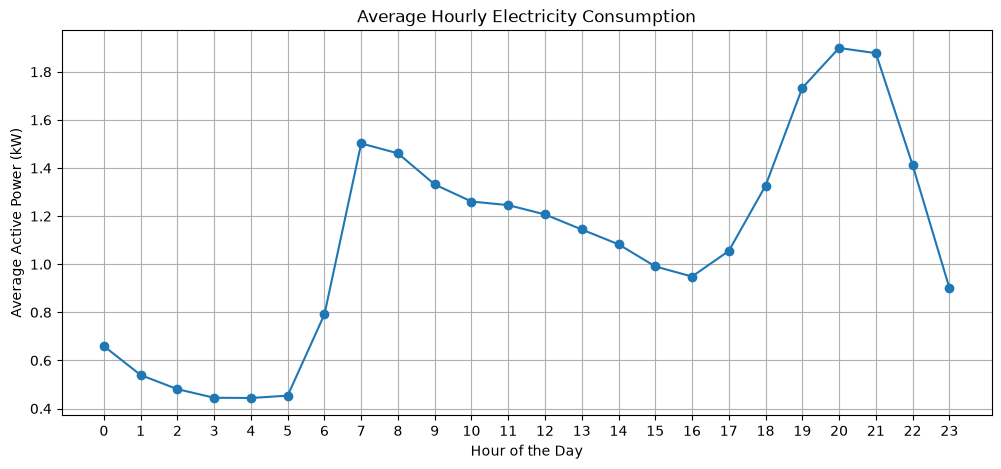

In [57]:
import matplotlib.pyplot as plt

# Set the figure size
plt.figure(figsize=(12, 5))

# Plot average power for each hour
plt.plot(
    hourly_consumption.index,
    hourly_consumption.values,
    marker='o'
)

# Add title and axis labels
plt.title('Average Hourly Electricity Consumption')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Active Power (kW)')

# Display all 24 hours on the x-axis
plt.xticks(range(24))

# Add grid lines
plt.grid(True)

# Display the plot
plt.show()

### Hourly Consumption Observations

- Electricity demand is lowest during the early morning
  hours, reaching approximately 0.444 kW at 04:00.
- A morning peak occurs at 07:00, with an average
  active power of approximately 1.502 kW.
- Consumption gradually decreases during the daytime.
- The highest average demand occurs at 20:00,
  reaching approximately 1.899 kW.
- The results reveal two distinct daily demand peaks,
  with the evening peak being higher than the morning peak.

### Identifying Peak and Off-Peak Hours

Identify the hours with the highest and lowest
average active power demand and compare their
electricity consumption levels.

In [58]:
# Identify the hour with the highest average power
peak_hour = hourly_consumption.idxmax()

# Identify the hour with the lowest average power
off_peak_hour = hourly_consumption.idxmin()

# Find the highest and lowest hourly average power
peak_power = hourly_consumption.max()
off_peak_power = hourly_consumption.min()

# Display the results
print("Peak hour:", peak_hour)
print("Peak power:", peak_power, "kW")

print("Off-peak hour:", off_peak_hour)
print("Off-peak power:", off_peak_power, "kW")

# Calculate the ratio between peak and off-peak demand
print("Peak to off-peak ratio:", peak_power / off_peak_power)

Peak hour: 20
Peak power: 1.8991032118663864 kW
Off-peak hour: 4
Off-peak power: 0.443846870604782 kW
Peak to off-peak ratio: 4.278735162148793


### Daily Electricity Consumption Analysis

Group electrical energy measurements by date and
calculate the total available energy consumption
for each day to identify daily demand variations.

In [59]:
# Extract the date from each timestamp
df_clean['Day'] = df_clean['Datetime'].dt.date

# Calculate total energy consumption for each day
daily_consumption = df_clean.groupby('Day')['Energy_kWh'].sum()

# Display the first ten days
daily_consumption.head(10)

Day
2006-12-16    20.152933
2006-12-17    56.507667
2006-12-18    36.730433
2006-12-19    27.769900
2006-12-20    37.095800
2006-12-21    28.618567
2006-12-22    39.022300
2006-12-23    79.556433
2006-12-24    42.500200
2006-12-25    45.718667
Name: Energy_kWh, dtype: float64

### Checking Daily Data Completeness

Count the number of available measurements for each
day. A complete day should contain 1,440 measurements.
Exclude incomplete days from daily consumption
comparisons to avoid misleading results.

In [60]:
# Count the number of measurements for each day
daily_counts = df_clean.groupby('Day')['Energy_kWh'].count()

# Identify days containing all 1440 measurements
complete_days = daily_counts[daily_counts == 1440]

# Select energy consumption for complete days only
daily_consumption_complete = daily_consumption.loc[complete_days.index]

# Display the number of complete and incomplete days
print("Total recorded days:", len(daily_counts))
print("Complete days:", len(complete_days))
print("Incomplete recorded days:", len(daily_counts) - len(complete_days))

Total recorded days: 1433
Complete days: 1409
Incomplete recorded days: 24


### Visualising Daily Electricity Consumption

Create a line plot showing daily electrical energy
consumption over the recording period. Display only
complete days and preserve gaps for incomplete days.

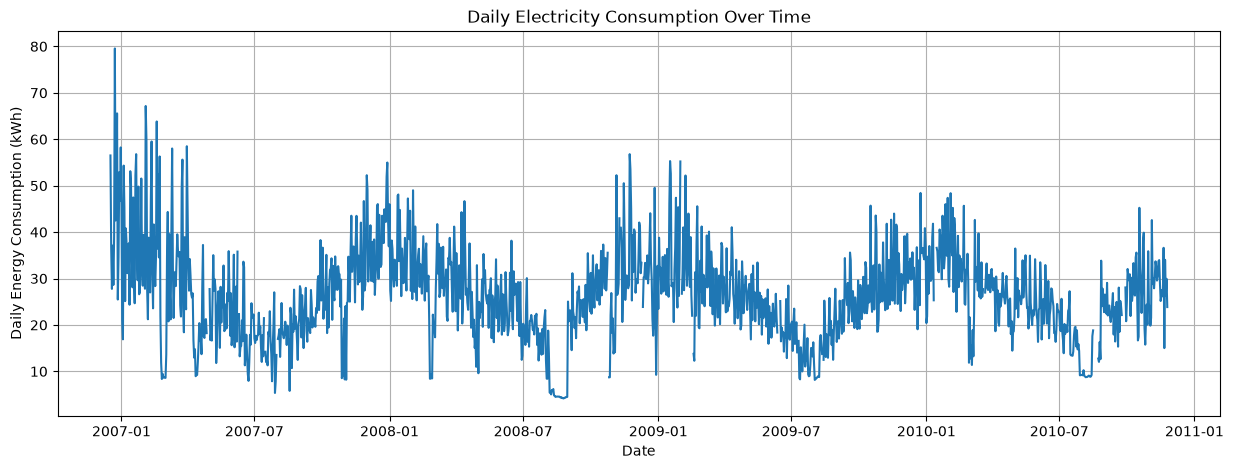

In [61]:
# Convert the date index into datetime format
daily_consumption_complete.index = pd.to_datetime(
    daily_consumption_complete.index
)

# Preserve missing days as gaps in the graph
daily_plot = daily_consumption_complete.asfreq('D')

# Create the figure
plt.figure(figsize=(15, 5))

# Plot daily energy consumption
plt.plot(daily_plot.index, daily_plot.values)

# Add title and axis labels
plt.title('Daily Electricity Consumption Over Time')
plt.xlabel('Date')
plt.ylabel('Daily Energy Consumption (kWh)')

plt.grid(True)
plt.show()

### Daily Consumption Observations

Daily electricity consumption shows a recurring
seasonal pattern, with higher consumption during
winter and lower consumption during summer.

The daily energy consumption varies considerably
throughout the recording period.

Seasonal variations may be associated with changes
in household activities, heating and lighting demand.

### Monthly Electricity Consumption Analysis

Group complete daily energy measurements by month
and calculate average daily energy consumption for
each calendar month to identify seasonal patterns.

In [62]:
# Group complete daily consumption values by month
monthly_consumption = daily_consumption_complete.groupby(
    daily_consumption_complete.index.month
).mean()

# Display average daily consumption for each month
monthly_consumption

Day
1     35.073151
2     31.373502
3     29.553152
4     25.157142
5     24.709719
6     21.870323
7     16.784208
8     13.632485
9     23.407507
10    27.300642
11    30.983235
12    35.647612
Name: Energy_kWh, dtype: float64

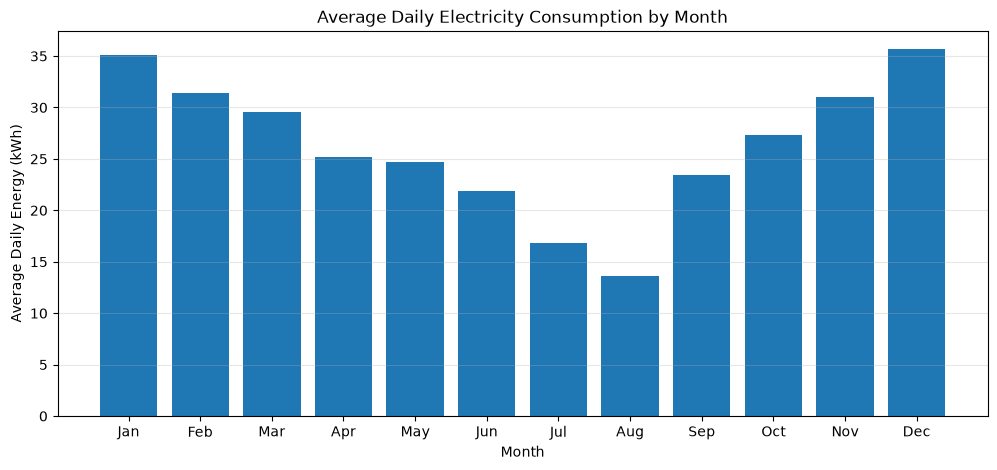

In [63]:
# Create a figure
plt.figure(figsize=(12, 5))

# Plot monthly average daily consumption
plt.bar(
    monthly_consumption.index,
    monthly_consumption.values
)

# Add title and axis labels
plt.title('Average Daily Electricity Consumption by Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Energy (kWh)')

# Replace month numbers with month names
plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

# Add horizontal grid lines
plt.grid(axis='y', alpha=0.3)

# Display the graph
plt.show()

### Distribution of Electricity Consumption

Create a histogram of global active power to analyse
the distribution of electricity demand and identify
the most frequently occurring power ranges.

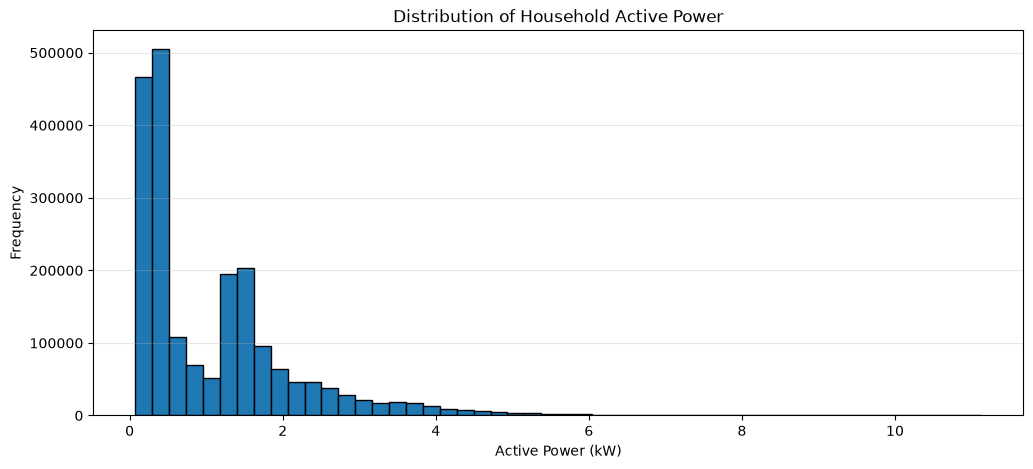

In [64]:
# Create a figure
plt.figure(figsize=(12, 5))

# Create a histogram of active power measurements
plt.hist(
    df_clean['Global_active_power'],
    bins=50,
    edgecolor='black'
)

# Add title and axis labels
plt.title('Distribution of Household Active Power')
plt.xlabel('Active Power (kW)')
plt.ylabel('Frequency')

# Add horizontal grid lines
plt.grid(axis='y', alpha=0.3)

# Display the histogram
plt.show()

### Histogram Observations

The distribution of active power is positively skewed.
The most frequent measurements occur at low power
levels, particularly below 0.6 kW.

Another noticeable concentration of measurements
appears between approximately 1.2 and 1.8 kW.

Higher power measurements occur less frequently,
creating a long right tail in the distribution.
These values may represent periods of high
household electricity demand.

## Final Conclusion

### Data Cleaning

The original household electricity consumption dataset
contained 2,075,259 observations.

Missing values were detected and classified into short
and long gaps. Linear interpolation was applied to
72 missing observations, while 25,907 remaining
missing observations were excluded.

No duplicate records or negative electrical measurements
were detected. Minor energy inconsistencies were
investigated and retained.

The IQR method identified 94,919 potential outliers,
representing approximately 4.63% of the cleaned dataset.
These observations were flagged and retained because
they may represent genuine electricity demand peaks.

### Data Analysis

The average active power was approximately 1.092 kW,
with a minimum of 0.076 kW and a maximum of 11.122 kW.

The hourly analysis identified two daily consumption
peaks. The morning peak occurred at 07:00, while the
highest average demand occurred at 20:00. The lowest
average demand occurred at 04:00.

The daily and monthly analyses revealed seasonal
consumption patterns, with higher electricity
consumption during winter and lower consumption
during summer.

December recorded the highest average daily energy
consumption of 35.65 kWh, while August recorded the
lowest value of 13.63 kWh.

The histogram showed a positively skewed distribution,
indicating that low power measurements are more
frequent than high power measurements.

### Limitations

Interpolated measurements are estimated values.
Long missing gaps may affect the statistical results.
Incomplete days were excluded from daily and monthly
comparisons. Statistical outliers were retained because
their validity could not be independently confirmed.

### Overall Conclusion

This project improved my understanding of data
cleaning, time-series analysis, statistical analysis
and data visualisation using Python.

The identified electricity consumption patterns can
support future work related to load forecasting,
energy management and smart grid flexibility.